# SNCF : exploration simple
But : d?couvrir les donn?es et choisir une question pour le projet.

Donn?es : [R?gularit? mensuelle TGV](https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/information/), demand?es dans l'[?nonc?](https://github.com/lambzcode/python_pour_la_prod/blob/main/enonce_projet_sncf.md).
Le CSV officiel est d?j? t?l?charg? dans `data/raw/`. On le lit sans le modifier.

Pr?par? le 14 octobre 2026 pour le cadrage pr?vu le 12 octobre. Une ligne repr?sente un mois et une liaison (d?part ? arriv?e).


## 1. Charger les donn?es

In [5]:
import sys
from pathlib import Path

print("Python utilisé :", sys.executable)
print("Dossier de travail :", Path.cwd())
print("Fichiers CSV :", list(Path("../data/raw").glob("*.csv")))

Python utilisé : /home/emman/projets/RailInsight-SNCF/.venv/bin/python
Dossier de travail : /home/emman/projets/RailInsight-SNCF/notebooks
Fichiers CSV : [PosixPath('../data/raw/regularite-mensuelle-tgv-aqst.csv')]


In [6]:
import pandas as pd
#import matplotlib.pyplot as plt
#from IPython.display import display

# Lire le fichier
df = pd.read_csv("../data/raw/regularite-mensuelle-tgv-aqst.csv", sep=";")
print("Lignes et colonnes :", df.shape)

Lignes et colonnes : (12907, 26)


## 2. Regarder les variables

In [2]:
display(df.dtypes.to_frame("Type"))
display(df.describe().T.round(2))
print("P?riode :", df["date"].min(), "?", df["date"].max())
display(df["service"].value_counts().to_frame("Nombre de lignes"))

P?riode : 2018-01 ? 2026-09


,Type
date,str
service,str
gare_depart,str
gare_arrivee,str
duree_moyenne,int64
nb_train_prevu,int64
nb_annulation,int64
commentaire_annulation,float64
nb_train_depart_retard,int64
retard_moyen_depart,float64


,count,mean,std,min,25%,50%,75%,max
duree_moyenne,12907.0,170.69,87.73,0.00,99.00,163.00,223.00,786.00
nb_train_prevu,12907.0,273.44,184.12,0.00,151.00,231.00,365.00,1104.00
nb_annulation,12907.0,8.27,21.81,0.00,0.00,2.00,7.00,297.00
commentaire_annulation,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nb_train_depart_retard,12907.0,86.70,88.75,0.00,22.00,52.00,127.00,598.00
retard_moyen_depart,12907.0,12.60,11.58,0.00,6.43,10.70,16.23,316.19
retard_moyen_tous_trains_depart,12907.0,3.22,5.02,-229.27,1.25,2.40,4.09,115.05
commentaire_retards_depart,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nb_train_retard_arrivee,12907.0,38.87,32.45,0.00,16.00,30.00,53.00,376.00
retard_moyen_arrivee,12907.0,35.62,15.61,-40.11,26.09,33.90,42.91,299.60


,Nombre de lignes
service,
National,11339
International,1568


## 3. V?rifier les donn?es
Les commentaires sont facultatifs. Les lignes signal?es ci-dessous sont ? v?rifier, pas ? corriger automatiquement.

In [3]:
# Valeurs manquantes et doublons
display(df.isna().sum().to_frame("Valeurs manquantes"))
print("Doublons complets :", df.duplicated().sum())
print("Doublons mois-liaison :", df.duplicated(["date", "service", "gare_depart", "gare_arrivee"]).sum())

# Quelques contr?les simples
circules = df["nb_train_prevu"] - df["nb_annulation"]
print("Annulations sup?rieures aux trains pr?vus :", (df["nb_annulation"] > df["nb_train_prevu"]).sum())
print("Retards sup?rieurs aux trains circul?s :", (df["nb_train_retard_arrivee"] > circules).sum())
print("Dur?es non positives :", (df["duree_moyenne"] <= 0).sum())
causes = df.filter(like="prct_cause_")
print("Sommes des causes ?loign?es de 100 % :", ((causes.sum(axis=1) - 100).abs() > 0.5).sum())

Doublons complets : 0
Doublons mois-liaison : 0
Annulations sup?rieures aux trains pr?vus : 63
Retards sup?rieurs aux trains circul?s : 63
Dur?es non positives : 73
Sommes des causes ?loign?es de 100 % : 282


,Valeurs manquantes
date,0
service,0
gare_depart,0
gare_arrivee,0
duree_moyenne,0
nb_train_prevu,0
nb_annulation,0
commentaire_annulation,12907
nb_train_depart_retard,0
retard_moyen_depart,0


## 4. Calculer un taux de retard
On divise les trains en retard ? l'arriv?e par les trains ayant circul?.
On garde seulement les lignes avec des effectifs coh?rents pour ce calcul.

Attention : le seuil de retard d?pend de la dur?e (5, 10 ou 15 minutes). Un train peut appara?tre sur plusieurs liaisons. Ces chiffres ne donnent donc pas un taux global SNCF.


In [4]:
# Travailler sur une copie
analyse = df.copy()
analyse["circules"] = circules
ok = ((analyse["nb_train_prevu"] > 0)
      & (analyse["nb_annulation"] >= 0)
      & (analyse["circules"] > 0)
      & (analyse["nb_train_retard_arrivee"] >= 0)
      & (analyse["nb_train_retard_arrivee"] <= analyse["circules"]))
analyse = analyse[ok].copy()
analyse["taux_retard"] = 100 * analyse["nb_train_retard_arrivee"] / analyse["circules"]
print("Lignes ?cart?es pour le calcul :", len(df) - len(analyse))
display(analyse["taux_retard"].describe().round(2))

Lignes ?cart?es pour le calcul : 73


count    12834.00
mean        14.93
std          8.44
min          0.00
25%          9.38
50%         13.36
75%         18.70
max        100.00
Name: taux_retard, dtype: float64

## 5. Quelques graphiques
Chaque ligne a le m?me poids dans ces graphiques. La m?diane ne repr?sente pas la ponctualit? globale du r?seau.

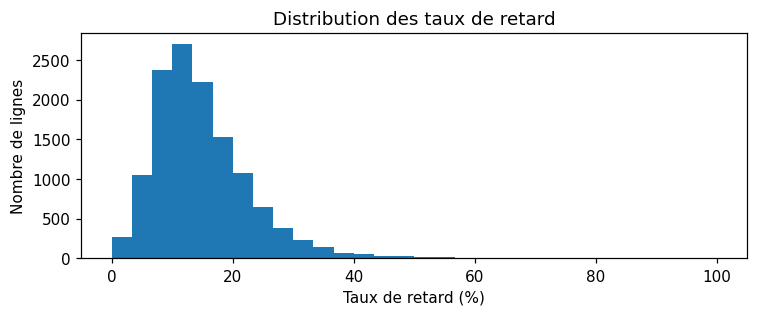

In [5]:
analyse["taux_retard"].plot.hist(bins=30, figsize=(7, 3))
plt.title("Distribution des taux de retard")
plt.xlabel("Taux de retard (%)")
plt.ylabel("Nombre de lignes")
plt.tight_layout()
plt.show()

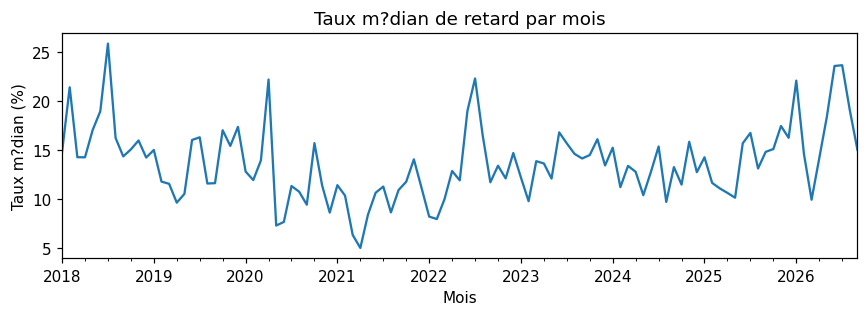

In [6]:
# ?volution de la m?diane par mois
analyse["mois"] = pd.to_datetime(analyse["date"])
analyse.groupby("mois")["taux_retard"].median().plot(figsize=(8, 3))
plt.title("Taux m?dian de retard par mois")
plt.xlabel("Mois")
plt.ylabel("Taux m?dian (%)")
plt.tight_layout()
plt.show()

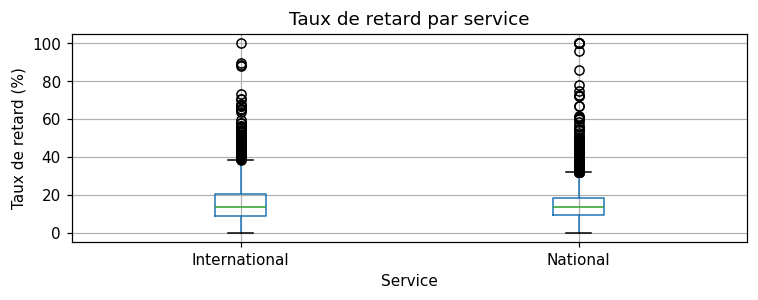

In [7]:
# Comparer les deux services
analyse.boxplot(column="taux_retard", by="service", figsize=(7, 3))
plt.suptitle("")
plt.title("Taux de retard par service")
plt.xlabel("Service")
plt.ylabel("Taux de retard (%)")
plt.tight_layout()
plt.show()

## 6. Choisir une probl?matique
| Question simple | Variables | Int?r?t | Limite |
|---|---|---|---|
| Quelles liaisons ont le plus de retards ? | Gares, mois, trains pr?vus, annul?s et en retard | Facile ? comprendre et utile pour comparer | Comparer la m?me p?riode et tenir compte des volumes et des seuils de retard |
| Y a-t-il plus de retards ? certaines p?riodes ? | Mois, liaison, taux de retard | Plusieurs ann?es disponibles | Les liaisons pr?sentes changent ; une variation ne prouve pas une saisonnalit? |
| Les causes de retard diff?rent-elles selon le service ? | Service, pourcentages de causes | Cat?gories d?j? pr?sentes | Certaines sommes sont incoh?rentes ; le sens des pourcentages doit ?tre confirm? |

**Question recommand?e : quelles liaisons ont le plus de retards ?**
Les variables n?cessaires sont pr?sentes. On pourra comparer les liaisons sur une m?me ann?e compl?te, en montrant aussi le nombre de trains. Ce classement reste ? r?aliser.


## 7. Synth?se pour la r?union
- **Donn?es :** 12 907 lignes et 26 variables, de janvier 2018 ? septembre 2026.
- **Constat :** le taux m?dian de retard est de **13.36 %** sur les lignes retenues. Ce n'est pas un taux national.
- **Qualit? :** aucun doublon ; deux colonnes de commentaires enti?rement vides. 63 lignes ont plus d'annulations que de trains pr?vus ; 282 ont une somme des causes ?loign?e de 100 %. Pour le calcul du taux, 73 lignes sont ?cart?es.
- **Choix :** comparer les retards par liaison sur une p?riode commune.
- **Limites :** donn?es mensuelles, seuil de retard variable, couverture diff?rente selon les liaisons.

Les chiffres ci-dessus sont calcul?s sur les donn?es t?l?charg?es. Les graphiques ne prouvent pas les raisons des retards ni une saisonnalit?.

**Suite possible, sans l'impl?menter ici :** v?rifier les anomalies, choisir une ann?e compl?te et comparer les liaisons avec leurs volumes de trains.

Toutes les cellules de code ont ?t? ex?cut?es. Aucun mod?le entra?n? ; donn?es brutes inchang?es.
